## Borehole heat transfer in a double U-tube borehole (parallel)

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pygfunction3 as gt3
import pygfunction as gt

#### Borehole parameters
A straight vertical borehole located at the origin (x=0, y=0) is used since the model is only dependent on the longitudinal position along the borehole.

In [2]:
# Borehole dimensions
L = 150.      # Borehole length (in meters)
D = 4.        # Borehole buried depth (in meters)
r_b = 0.075   # Borehole radius (in meters)
x = 0.        # Borehole position x on the horizontal plane (in meters)
y = 0.        # Borehole position y on the horizontal plane (in meters)
borehole = gt3.Borehole(L, D, r_b, [x, y])

# Pipe dimensions
n_p = 4             # Number of pipes
# Pipe inner radius (m)
r_p_in = 0.018 * np.ones(n_p)
# Pipe outer radius (m)
r_p_out = 0.02 * np.ones(n_p)

# Pipe positions
# Single U-tube [(x_1, y_1), (x_2, y_2)]
p = [(0.032, 0.00), (0.0, 0.032), (-0.028, 0.003), (0.00, -0.03)]

# Pipe properties
k_p = 0.4           # Pipe thermal conductivity (W/m.K)
epsilon = 2.12e-5   # Pipe roughness (in meters)

# Ground properties
k_s = 2.5           # Ground thermal conductivity (W/m.K)

# Grout properties
k_b = 1.5           # Grout thermal conductivity (W/m.K)

#### Fluid Properties
The fluid is propylene-glycol (20%) and the internal thermal resistances were calculated for a typical borehole configuration using the multipole method.

In [3]:
m_flow = 0.1      # Fluid mass flow rate (in kg/s)
T_nominal = 20.
fluid = gt3.Fluid.from_scp(
    'PropyleneGlycol', T_nominal, x=0.2
)
cp_f = fluid.specific_heat()  # Fluid specific heat capacity (in J/kg.K)

#### Simulation conditions

In [4]:
# Inlet fluid temperature (in degrees Celsius)
T_f_in = -1.
# Borehole wall temperature (in degrees Celsius)
f_T_b = lambda _xi, _N: 1. + _xi**(_N - 1) - _xi / 3

### Solution using pygfunction3

#### Parameters for the evaluation of the borehole heat transfer

In [5]:
# Basis functions
n_nodes = 11
basis = gt3.Basis(n_nodes)
# Evaluation points
T_b_nodes = f_T_b(basis.xi, basis.n_nodes)
n_eval = 201
xi_eval = np.linspace(-1., 1., num=n_eval)
s_eval = borehole.longitudinal_position(xi_eval)
T_b_eval = f_T_b(xi_eval, basis.n_nodes)

In [6]:
# Pipe object
pipe = gt3.pipe.MultipleUTubeParallel(p, r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon)
pipe_reversed = gt3.pipe.MultipleUTubeParallel(p[::-1], r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon)

# Fluid temperature profile along the borehole
T_f = pipe.temperature(borehole, basis, xi_eval, m_flow, T_f_in, T_b_nodes)
T_f_reversed = pipe_reversed.temperature(borehole, basis, xi_eval, -m_flow, T_f_in, T_b_nodes)
# Outlet fluid temperature
T_f_out = pipe.outlet_temperature(borehole, basis, m_flow, T_f_in, T_b_nodes)
T_f_out_reversed = pipe_reversed.outlet_temperature(borehole, basis, -m_flow, T_f_in, T_b_nodes)
# Heat extraction rate along the borehole
q = pipe.heat_extraction_rate(borehole, basis, xi_eval, m_flow, T_f_in, T_b_nodes)
q_reversed = pipe_reversed.heat_extraction_rate(borehole, basis, xi_eval, -m_flow, T_f_in, T_b_nodes)
# Average heat extraction rate
q_avg = pipe.average_heat_extraction_rate(borehole, basis, m_flow, T_f_in, T_b_nodes)
q_avg_reversed = pipe_reversed.average_heat_extraction_rate(borehole, basis, -m_flow, T_f_in, T_b_nodes)
# Effective borehole thermal resistance
R_b = pipe.effective_borehole_thermal_resistance(borehole, m_flow)
R_b_reversed = pipe_reversed.effective_borehole_thermal_resistance(borehole, -m_flow)

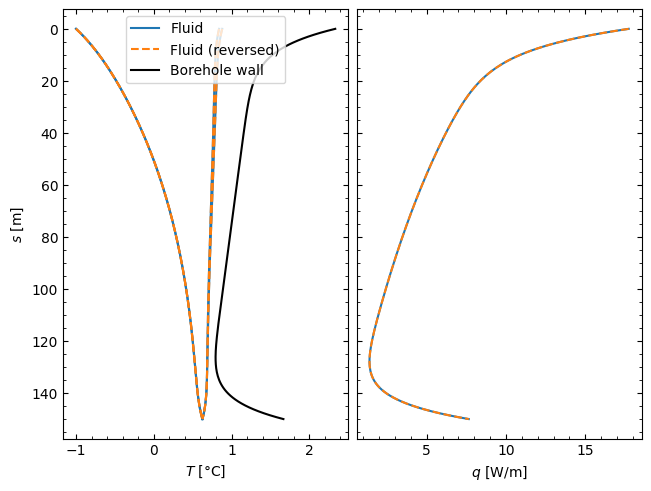

In [7]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$T$ [°C]', '$s$ [m]'], inverse_y=True)
line = axs[0].plot(T_f[:, 0], s_eval, label='Fluid')
axs[0].plot(T_f[:, 1:], s_eval, color=line[0].get_color())
line = axs[0].plot(T_f_reversed[:, 0], s_eval, '--', label='Fluid (reversed)')
axs[0].plot(T_f_reversed[:, 1:], s_eval, '--', color=line[0].get_color())
axs[0].plot(T_b_eval, s_eval, 'k-', label='Borehole wall')
axs[0].legend()
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel('$q$ [W/m]')
axs[1].plot(q, s_eval)
axs[1].plot(q_reversed, s_eval, '--')
plt.show()

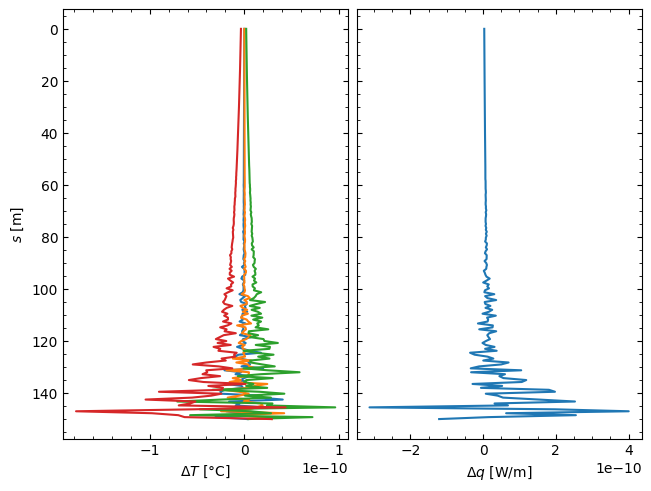

In [8]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$\Delta T$ [°C]', '$s$ [m]'], inverse_y=True)
line = axs[0].plot(T_f - np.flip(T_f_reversed, axis=1), s_eval)
# axs[0].legend()
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel(r'$\Delta q$ [W/m]')
axs[1].plot(q - q_reversed, s_eval)
plt.show()

### Solution using pygfunction2

In [9]:
# Borehole object
borehole_pygfunction = gt.boreholes.Borehole(L, D, r_b, x, y)
# Evaluation points
n_segments = 51
xi_edges = np.linspace(-1., 1., num=n_segments + 1)
xi_segments = 0.5 * (xi_edges[1:] + xi_edges[:-1])
s_segments = borehole.longitudinal_position(xi_segments)
T_b_segments = f_T_b(xi_segments, n_nodes)

In [10]:
# Pipe object
h_fluid = gt.pipes.convective_heat_transfer_coefficient_circular_pipe(
    m_flow / 2,
    r_p_in[0],
    fluid.viscosity(),
    fluid.density(),
    fluid.conductivity(),
    fluid.specific_heat(),
    epsilon
)
R_fluid = 1. / (h_fluid * 2. * np.pi * r_p_in[0])
R_pipe = gt.pipes.conduction_thermal_resistance_circular_pipe(
    r_p_in[0], r_p_out[0], k_p
)
R_fp = R_fluid + R_pipe
pipe_pygfunction = gt.pipes.MultipleUTube(
    p, r_p_in[0], r_p_out[0], borehole_pygfunction, k_s, k_b, R_fp, 2, J=3, config='parallel'
)

# Fluid temperature profile along the borehole
T_f_pygfunction = pipe_pygfunction.get_temperature(s_eval, T_f_in, T_b_segments, m_flow, np.full(1, cp_f))
# Outlet fluid temperature
T_f_out_pygfunction = pipe_pygfunction.get_outlet_temperature(T_f_in, T_b_segments, m_flow, np.full(1, cp_f))
# Heat extraction rate along the borehole
q_pygfunction = pipe_pygfunction.get_borehole_heat_extraction_rate(T_f_in, T_b_segments, m_flow, np.full(1, cp_f)) * n_segments / borehole_pygfunction.H
# Average heat extraction rate
q_avg_pygfunction = pipe_pygfunction.get_total_heat_extraction_rate(T_f_in, T_b_segments, m_flow, np.full(1, cp_f)) / borehole_pygfunction.H
# Effective borehole thermal resistance
R_b_pygfunction = pipe_pygfunction.effective_borehole_thermal_resistance(m_flow, np.full(1, cp_f))

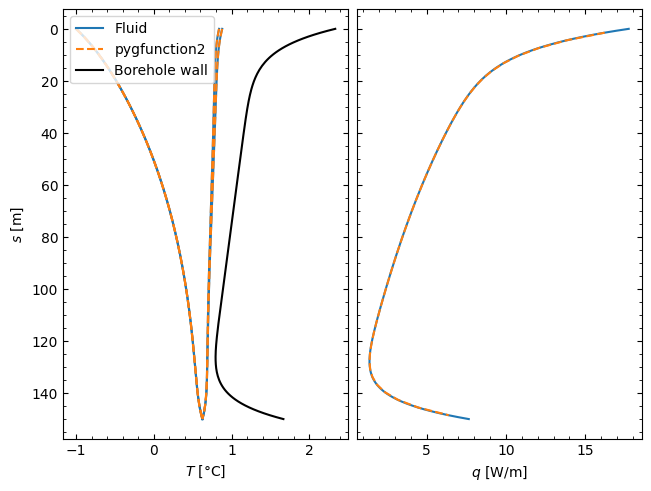

In [11]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$T$ [°C]', '$s$ [m]'], inverse_y=True)
line = axs[0].plot(T_f[:, 0], s_eval, label='Fluid')
axs[0].plot(T_f[:, 1:], s_eval, color=line[0].get_color())
line = axs[0].plot(T_f_pygfunction[:, 0], s_eval, '--', label='pygfunction2')
axs[0].plot(T_f_pygfunction[:, 1:], s_eval, '--', color=line[0].get_color())
axs[0].plot(T_b_eval, s_eval, 'k-', label='Borehole wall')
axs[0].legend()
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel('$q$ [W/m]')
axs[1].plot(q, s_eval)
axs[1].plot(q_pygfunction, s_segments, '--')
plt.show()

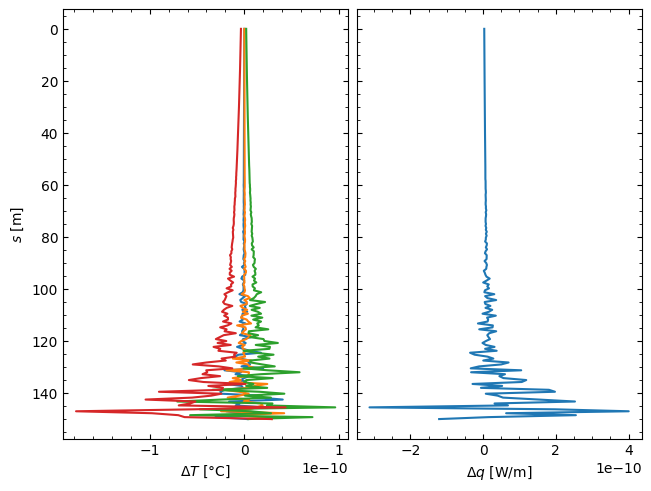

In [12]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$\Delta T$ [°C]', '$s$ [m]'], inverse_y=True)
line = axs[0].plot(T_f - np.flip(T_f_reversed, axis=1), s_eval)
# axs[0].legend()
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel(r'$\Delta q$ [W/m]')
axs[1].plot(q - q_reversed, s_eval)
plt.show()

### Solution using a finite difference model
A finite difference model is used for validation of the solution. The finite difference model uses evenly spaced longitudinal positions $s_i$ along the length of each pipe.

In [13]:
class FiniteDifferenceSingleUTube:

    def __init__(self, R_d, L, num=101):
        self.R_d = R_d
        self.L = L
        self.num = num
        self.s = np.linspace(0., L, num=num)

    def solve(self, T_f_in, f_T_b, m_flow, cp_f):
        A = self.system_of_equations(m_flow, cp_f)
        B = self.boundary_condition(T_f_in, f_T_b, m_flow, cp_f)
        X = np.linalg.solve(A, B)
        T_f = X.reshape(-1, 4, order='F')
        xi = np.linspace(-1., 1., num=self.num)
        T_b = f_T_b(xi)
        G = 1 / self.R_d
        R_b = 1 / np.trace(G)
        q = T_b / R_b - T_f @ np.diag(G)
        return q, T_f

    def boundary_condition(self, T_f_in, f_T_b, m_flow, cp_f):
        xi = np.linspace(-1., 1., num=self.num)
        xi = 0.5 * (xi[:-1] + xi[1:])
        T_b = f_T_b(xi)
        ds = self.L / (self.num - 1.)
        beta_1 = 2. / (m_flow * cp_f * self.R_d[0, 0])
        beta_2 = 2. / (m_flow * cp_f * self.R_d[1, 1])
        beta_3 = 2. / (m_flow * cp_f * self.R_d[2, 2])
        beta_4 = 2. / (m_flow * cp_f * self.R_d[3, 3])
        B = np.concatenate([np.array([T_f_in, T_f_in]), ds * beta_1 * T_b, ds * beta_2 * T_b, ds * beta_3 * T_b, ds * beta_4 * T_b, np.zeros(2)])     
        return B

    def system_of_equations(self, m_flow, cp_f):
        ds = self.L / (self.num - 1.)
        beta_1 = 2. / (m_flow * cp_f * self.R_d[0, 0])
        beta_12 = 2. / (m_flow * cp_f * self.R_d[0, 1])
        beta_13 = 2. / (m_flow * cp_f * self.R_d[0, 2])
        beta_14 = 2. / (m_flow * cp_f * self.R_d[0, 3])
        beta_2 = 2. / (m_flow * cp_f * self.R_d[1, 1])
        beta_23 = 2. / (m_flow * cp_f * self.R_d[1, 2])
        beta_24 = 2. / (m_flow * cp_f * self.R_d[1, 3])
        beta_3 = 2. / (m_flow * cp_f * self.R_d[2, 2])
        beta_34 = 2. / (m_flow * cp_f * self.R_d[2, 3])
        beta_4 = 2. / (m_flow * cp_f * self.R_d[3, 3])
        N = self.num - 1
        A_11 = (1. + 0.5 * ds * (beta_1 + beta_12 + beta_13 + beta_14)) * np.eye(N, M=N+1, k=1)
        A_11 = A_11 + (-1. + 0.5 * ds * (beta_1 + beta_12 + beta_13 + beta_14)) * np.eye(N, M=N+1, k=0)
        A_12 = -0.5 * ds * beta_12 * np.eye(N, M=N+1, k=1)
        A_12 = A_12 - 0.5 * ds * beta_12 * np.eye(N, M=N+1, k=0)
        A_13 = -0.5 * ds * beta_13 * np.eye(N, M=N+1, k=1)
        A_13 = A_13 - 0.5 * ds * beta_13 * np.eye(N, M=N+1, k=0)
        A_14 = -0.5 * ds * beta_14 * np.eye(N, M=N+1, k=1)
        A_14 = A_14 - 0.5 * ds * beta_14 * np.eye(N, M=N+1, k=0)
        A_21 = -0.5 * ds * beta_12 * np.eye(N, M=N+1, k=1)
        A_21 = A_21 - 0.5 * ds * beta_12 * np.eye(N, M=N+1, k=0)
        A_22 = (1. + 0.5 * ds * (beta_2 + beta_12 + beta_23 + beta_24)) * np.eye(N, M=N+1, k=1)
        A_22 = A_22 + (-1. + 0.5 * ds * (beta_2 + beta_12 + beta_23 + beta_24)) * np.eye(N, M=N+1, k=0)
        A_23 = -0.5 * ds * beta_23 * np.eye(N, M=N+1, k=1)
        A_23 = A_23 - 0.5 * ds * beta_23 * np.eye(N, M=N+1, k=0)
        A_24 = -0.5 * ds * beta_24 * np.eye(N, M=N+1, k=1)
        A_24 = A_24 - 0.5 * ds * beta_24 * np.eye(N, M=N+1, k=0)
        A_31 = -0.5 * ds * beta_13 * np.eye(N, M=N+1, k=0)
        A_31 = A_31 - 0.5 * ds * beta_13 * np.eye(N, M=N+1, k=1)
        A_32 = -0.5 * ds * beta_23 * np.eye(N, M=N+1, k=0)
        A_32 = A_32 - 0.5 * ds * beta_23 * np.eye(N, M=N+1, k=1)
        A_33 = (1. + 0.5 * ds * (beta_3 + beta_13 + beta_23 + beta_34)) * np.eye(N, M=N+1, k=0)
        A_33 = A_33 + (-1. + 0.5 * ds * (beta_3 + beta_13 + beta_23 + beta_34)) * np.eye(N, M=N+1, k=1)
        A_34 = -0.5 * ds * beta_34 * np.eye(N, M=N+1, k=0)
        A_34 = A_34 - 0.5 * ds * beta_34 * np.eye(N, M=N+1, k=1)
        A_41 = -0.5 * ds * beta_14 * np.eye(N, M=N+1, k=0)
        A_41 = A_41 - 0.5 * ds * beta_14 * np.eye(N, M=N+1, k=1)
        A_42 = -0.5 * ds * beta_24 * np.eye(N, M=N+1, k=0)
        A_42 = A_42 - 0.5 * ds * beta_24 * np.eye(N, M=N+1, k=1)
        A_43 = -0.5 * ds * beta_34 * np.eye(N, M=N+1, k=0)
        A_43 = A_43 - 0.5 * ds * beta_34 * np.eye(N, M=N+1, k=1)
        A_44 = (1. + 0.5 * ds * (beta_4 + beta_14 + beta_24 + beta_34)) * np.eye(N, M=N+1, k=0)
        A_44 = A_44 + (-1. + 0.5 * ds * (beta_4 + beta_14 + beta_24 + beta_34)) * np.eye(N, M=N+1, k=1)
        connect = np.zeros((2, 4 * N + 4))
        # Pipe 0 to pipe 2 at bottom
        connect[0, N] = -1.
        connect[0, 3 * N + 2] = 1.
        # Pipe 1 to pipe 3 at bottom
        connect[1, 2 * N + 1] = -1.
        connect[1, 4 * N + 3] = 1.
        A = np.block(
            [
             [np.eye(1), np.zeros((1, 4 * N + 3))],
             [np.zeros((1, N + 1)), np.eye(1), np.zeros((1, 3 * N + 2))],
             [A_11, A_12, A_13, A_14],
             [A_21, A_22, A_23, A_24],
             [A_31, A_32, A_33, A_34],
             [A_41, A_42, A_43, A_44],
             [connect]
             ]
        )
        return A

In [14]:
borehole_FD = FiniteDifferenceSingleUTube(pipe.thermal_resistances(m_flow), L, num=n_eval)

# Heat extraction rate and fluid temperature profile along the borehole
q_FD, T_f_FD = borehole_FD.solve(T_f_in, lambda _xi: f_T_b(_xi, n_nodes), m_flow, cp_f)
# Outlet fluid temperature
T_f_out_FD = T_f_FD[0, -1]
# Average heat extraction rate
q_avg_FD = 0.5 * np.mean(q_FD[:-1] + q_FD[1:])

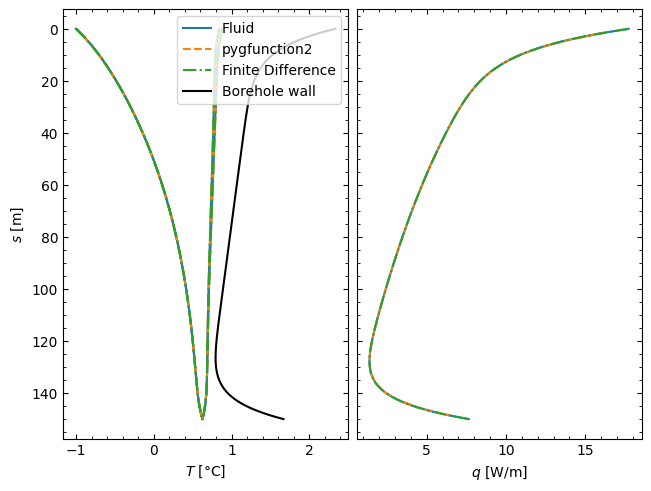

In [15]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$T$ [°C]', '$s$ [m]'], inverse_y=True)
line = axs[0].plot(T_f[:, 0], s_eval, label='Fluid')
axs[0].plot(T_f[:, 1:], s_eval, color=line[0].get_color())
line = axs[0].plot(T_f_pygfunction[:, 0], s_eval, '--', label='pygfunction2')
axs[0].plot(T_f_pygfunction[:, 1:], s_eval, '--', color=line[0].get_color())
line = axs[0].plot(T_f_FD[:, 0], s_eval, '-.', label='Finite Difference')
axs[0].plot(T_f_FD[:, 1:], s_eval, '-.', color=line[0].get_color())
axs[0].plot(T_b_eval, s_eval, 'k-', label='Borehole wall')
axs[0].legend()
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel('$q$ [W/m]')
axs[1].plot(q, s_eval)
axs[1].plot(q_pygfunction, s_segments, '--')
axs[1].plot(q_FD, s_eval, '-.')
plt.show()

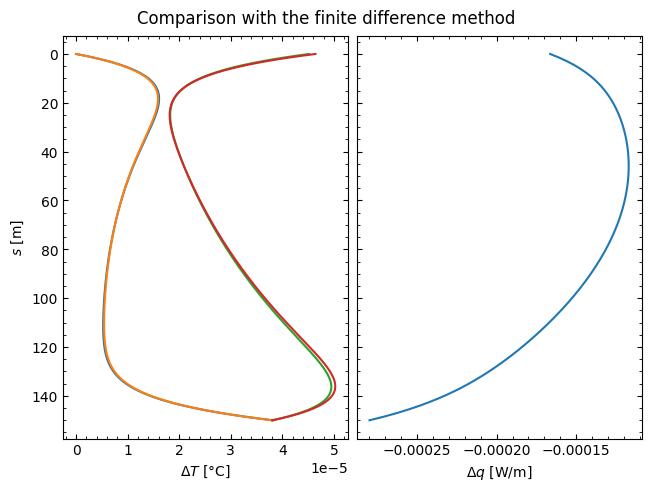

In [16]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
fig.suptitle('Comparison with the finite difference method')
axs[0] = gt3.plot._format_axis(axs[0], [r'$\Delta T$ [°C]', '$s$ [m]'], inverse_y=True)
line = axs[0].plot(T_f - T_f_FD, s_eval, label='Fluid')
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel(r'$\Delta q$ [W/m]')
axs[1].plot(q - q_FD, s_eval)
plt.show()

In [17]:
print(f'Outlet fluid temperature (pygfunction3): {T_f_out:.4f} °C')
print(f'Outlet fluid temperature (pygfunction3, reversed): {T_f_out_reversed:.4f} °C')
print(f'Outlet fluid temperature (pygfunction2): {T_f_out_pygfunction:.4f} °C')
print(f'Outlet fluid temperature (Finite Difference): {T_f_out_FD:.4f} °C')
print(f'Average heat extraction rate (pygfunction3): {q_avg:.4f} W/m')
print(f'Average heat extraction rate (pygfunction3, reversed): {q_avg_reversed:.4f} W/m')
print(f'Average heat extraction rate (pygfunction2): {q_avg_pygfunction:.4f} W/m')
print(f'Average heat extraction rate (Finite Difference): {q_avg_FD:.4f} W/m')
print(f'Effective borehole thermal resistance (pygfunction3): {R_b:.6f} K.m/W')
print(f'Effective borehole thermal resistance (pygfunction3, reversed): {R_b_reversed:.6f} K.m/W')
print(f'Effective borehole thermal resistance (pygfunction2): {R_b_pygfunction:.6f} K.m/W')

Outlet fluid temperature (pygfunction3): 0.8597 °C
Outlet fluid temperature (pygfunction3, reversed): 0.8597 °C
Outlet fluid temperature (pygfunction2): 0.8589 °C
Outlet fluid temperature (Finite Difference): 0.8798 °C
Average heat extraction rate (pygfunction3): 4.9303 W/m
Average heat extraction rate (pygfunction3, reversed): 4.9303 W/m
Average heat extraction rate (pygfunction2): 4.9283 W/m
Average heat extraction rate (Finite Difference): 4.9311 W/m
Effective borehole thermal resistance (pygfunction3): 0.251638 K.m/W
Effective borehole thermal resistance (pygfunction3, reversed): 0.251638 K.m/W
Effective borehole thermal resistance (pygfunction2): 0.251638 K.m/W
